# Project SQL - FDA RECALL DATABASE

## Use SQL queries to pull specific information

Like with the Chinook data base, do NOT pull all the data and then filter using DataFrame methods etc.

Write your question and then answer it using the SQL statements below.  Be sure to use guardrails ( e.g. dryrun ).



In [12]:
from google.colab import auth
from google.cloud import bigquery
from google.colab import userdata
import pandas as pd
import duckdb


In [2]:
auth.authenticate_user()
print('Authenticated')


Authenticated


In [5]:
project_id = userdata.get('bq_billing_project_id')

In [8]:
client = bigquery.Client(project=project_id)

In [16]:
def bq_query(query, max_gb=1):
    # Guardrail 1: dry run estimates the size without running the query
    dry_config = bigquery.QueryJobConfig(dry_run=True, use_query_cache=False)
    gb = client.query(query, job_config=dry_config).total_bytes_processed / 1e9
    print(f"Dry run: {gb:.4f} GB")

    if gb > max_gb:
        print("Too large. Query not run.")
        return None

    # Guardrail 2: hard limit on bytes billed
    real_config = bigquery.QueryJobConfig(maximum_bytes_billed=int(max_gb * 1e9))
    df = client.query(query, job_config=real_config).to_dataframe()

    # DuckDB can't read BigQuery's 'dbdate' type, so convert to normal dates
    for col in df.columns:
        if str(df[col].dtype) == 'dbdate':
            df[col] = pd.to_datetime(df[col].astype(str), errors='coerce')
    return df

### Basic Queries


#### SELECT (with * and with column names)


What does a recall record look like?

In [10]:
# Step 1: BigQuery (guarded) - get 5 full recall records
query = '''
  SELECT *
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  LIMIT 5
'''
print(query)
sample = bq_query(query)
sample


  SELECT *
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  LIMIT 5

Dry run: 0.0154 GB


,classification,center_classification_date,report_date,postal_code,termination_date,recall_initiation_date,recall_number,city,more_code_info,event_id,...,reason_for_recall,initial_firm_notification,status,product_type,country,product_description,code_info,address_1,address_2,product_quantity
0,Class II,2020-01-22,2020-01-29,07041-1416,2023-07-21,2020-01-10,D-0799-2020,Millburn,uau,84685,...,Defective Container: loose aluminum cap crimp ...,Letter,Terminated,Drugs,United States,"NETSPOT, (kit for the preparation of Ga 68 dot...","Lot #: PG1919025, Exp. 07/11/2020; PG1919026, ...",57 E Willow St,nan,4295 Kits
1,Class III,2022-04-06,2022-04-13,07041-1416,2023-01-04,2022-03-18,D-0747-2022,Millburn,uau,89885,...,Subpotent Drug: low out-of-specification resul...,Letter,Terminated,Drugs,United States,NETSPOT (kit for the preparation of Ga 68 dota...,Lot # (Vial 1)/kit: (F03221004 vial) in kit PG...,57 E Willow St,nan,"14,089 kits"
2,Class II,2021-05-24,2021-06-02,43017-1091,2024-06-17,2021-03-15,D-0486-2021,Dublin,uau,87512,...,CGMP Deviations: Intermittent exposure to temp...,Letter,Terminated,Drugs,United States,"Triumeq (abacavir, dolutegravir, and lamivudin...",GS5G,7000 Cardinal Pl,nan,2264 bottles
3,Class II,2026-10-23,2026-10-28,43228-9579,NaT,2026-10-06,D-0076-2027,Columbus,uau,100046,...,Failed Tablet/Capsule Specifications: Failed t...,Letter,Ongoing,Drugs,United States,"Abirtega (abiraterone acetate) USP, 250 mg, 12...","Lot #: 3047, Exp Date July 2027.",1809 Wilson Rd,nan,2136 bottles
4,Class II,2026-10-23,2026-11-04,07407-1317,NaT,2026-10-09,D-0074-2027,Elmwood Park,uau,100128,...,Labeling: Not Elsewhere Classified,nan,Ongoing,Drugs,United States,"Abiraterone Acetate Tablets USP 500 mg, 60-cou...","Lot #: 13250135, Exp. Date 11/2027",619 River Dr,nan,1296 bottles


In [22]:
# Step 2: DuckDB - SELECT with column names, from the small table we already have
duckdb.query('''
  SELECT recalling_firm, classification, reason_for_recall
  FROM sample
''').df()

NotImplementedException: Not implemented Error: Data type 'dbdate' not recognized

In [23]:
# Who recalled what and why?

query = '''
  SELECT column_name, data_type
  FROM `bigquery-public-data.fda_drug.INFORMATION_SCHEMA.COLUMNS`
  WHERE table_name = 'drug_enforcement'
  ORDER BY ordinal_position
'''
print(query)
columns = bq_query(query)
columns


  SELECT column_name, data_type
  FROM `bigquery-public-data.fda_drug.INFORMATION_SCHEMA.COLUMNS`
  WHERE table_name = 'drug_enforcement'
  ORDER BY ordinal_position

Dry run: 0.0105 GB


,column_name,data_type
0,classification,STRING
1,center_classification_date,DATE
2,report_date,DATE
3,postal_code,STRING
4,termination_date,DATE
5,recall_initiation_date,DATE
6,recall_number,STRING
7,city,STRING
8,more_code_info,STRING
9,event_id,INT64


In [24]:
# When is the first and last recall date

query = '''
  SELECT MIN(recall_initiation_date) AS first_recall,
         MAX(recall_initiation_date) AS last_recall,
         COUNT(*) AS n_rows,
         COUNT(DISTINCT event_id) AS n_events
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
'''
print(query)
summary = bq_query(query)
summary


  SELECT MIN(recall_initiation_date) AS first_recall,
         MAX(recall_initiation_date) AS last_recall,
         COUNT(*) AS n_rows,
         COUNT(DISTINCT event_id) AS n_events
  FROM `bigquery-public-data.fda_drug.drug_enforcement`

Dry run: 0.0003 GB


,first_recall,last_recall,n_rows,n_events
0,2006-02-24,2026-10-23,18110,4740


In [25]:
# How many states and countries have records
query = '''
  SELECT COUNT(DISTINCT state) AS n_states,
         COUNT(DISTINCT country) AS n_countries
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
'''
print(query)
places = bq_query(query)
places


  SELECT COUNT(DISTINCT state) AS n_states,
         COUNT(DISTINCT country) AS n_countries
  FROM `bigquery-public-data.fda_drug.drug_enforcement`

Dry run: 0.0003 GB


,n_states,n_countries
0,50,26


#### WHERE


In [26]:
# Q: Which recalls are Class I (the most serious level)?
query = '''
  SELECT recalling_firm, product_description, reason_for_recall
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  WHERE classification = 'Class I'
'''
print(query)
class_1 = bq_query(query)
print(class_1.shape)
class_1.head()


  SELECT recalling_firm, product_description, reason_for_recall
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  WHERE classification = 'Class I'

Dry run: 0.0062 GB
(1753, 3)


,recalling_firm,product_description,reason_for_recall
0,Hikma Pharmaceuticals USA Inc.,"Acetaminophen Injection, 1,000 mg per 100 mL (...",Labeling: Label Mix-up: a bag of Dexmedetomidi...
1,A-S Medication Solutions LLC.,"Acetaminophen, Extra Strength, Aspirin Free, 5...",Labeling: Label Mix-up; The bottle of over-the...
2,A-S Medication Solutions LLC,"Acetaminophen Extra Strength Tablets, 500 mg e...",Labeling: Label Mix-Up: Some bottles of Acetam...
3,Aurobindo Pharma USA Inc,"Healthy Living Acetaminophen, Aspirin (NSAID) ...",Labeling: Missing Label - some bottles are mis...
4,Zydus Pharmaceuticals (USA) Inc,Acyclovir Sodium Injection 1000mg/20mL (50mg/m...,Crystallization: customer complaints for cryst...


#### AND


In [27]:
# Q: Which Class I recalls are still ongoing?
query = '''
  SELECT recalling_firm, product_description, recall_initiation_date
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  WHERE classification = 'Class I'
    AND status = 'Ongoing'
'''
print(query)
ongoing = bq_query(query)
print(ongoing.shape)
ongoing.head()


  SELECT recalling_firm, product_description, recall_initiation_date
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  WHERE classification = 'Class I'
    AND status = 'Ongoing'

Dry run: 0.0045 GB
(231, 3)


,recalling_firm,product_description,recall_initiation_date
0,Hikma Pharmaceuticals USA Inc.,"Acetaminophen Injection, 1,000 mg per 100 mL (...",2024-07-08
1,Aurobindo Pharma USA Inc,"Healthy Living Acetaminophen, Aspirin (NSAID) ...",2024-07-11
2,"Par Health USA, LLC","Argatroban Injection, USP, 250 mg/2.5mL (100 m...",2026-10-13
3,"Par Health USA, LLC","Argatroban Injection, USP, 250 mg/2.5mL (100 m...",2026-10-13
4,Camber Pharmaceuticals Inc.,"Atovaquone Oral Suspension USP, 750 mg/5 mL, P...",2023-03-13


#### OR


In [28]:
# Q: Which recalls came from firms in New Mexico or Texas?
query = '''
  SELECT recalling_firm, city, state, classification
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  WHERE state = 'NM'
     OR state = 'TX'
'''
print(query)
nm_tx = bq_query(query)
print(nm_tx.shape)
nm_tx.head()


  SELECT recalling_firm, city, state, classification
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  WHERE state = 'NM'
     OR state = 'TX'

Dry run: 0.0010 GB
(1013, 4)


,recalling_firm,city,state,classification
0,"Allergan Sales, LLC",Waco,TX,Class III
1,"Allergan Sales, LLC",Waco,TX,Class III
2,"Allergan Sales, LLC",Waco,TX,Class III
3,"Allergan Sales, LLC",Waco,TX,Class II
4,"CareFusion 213, LLC",El Paso,TX,Class II


#### LIKE (with % or _ wildcard)


In [29]:
# Q: How many recalls mention sterility problems?
# LOWER() makes the search ignore capital letters
query = '''
  SELECT recalling_firm, reason_for_recall
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  WHERE LOWER(reason_for_recall) LIKE '%steril%'
'''
print(query)
sterility = bq_query(query)
print(sterility.shape)
sterility.head()


  SELECT recalling_firm, reason_for_recall
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  WHERE LOWER(reason_for_recall) LIKE '%steril%'

Dry run: 0.0025 GB
(6756, 2)


,recalling_firm,reason_for_recall
0,"Efficient Laboratories, Inc.",Microbial Contamination of Non-Sterile Products
1,Regeneron Pharmaceuticals Inc,Lack of Assurance of Sterility: Complaints of ...
2,Regeneron Pharmaceuticals Inc,Lack of Assurance of Sterility: Complaints of ...
3,"Endo Pharmaceuticals, Inc.",Lack of Assurance of Sterility: Defective cont...
4,"Genentech, Inc.",Lack of Assurance of Sterility: Deformed stopp...


#### BETWEEN


In [30]:
# Q: Which recalls started during the COVID years (2020-2021)?
query = '''
  SELECT recalling_firm, classification, recall_initiation_date
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  WHERE recall_initiation_date BETWEEN '2020-01-01' AND '2021-12-31'
'''
print(query)
covid_era = bq_query(query)
print(covid_era.shape)
covid_era.head()


  SELECT recalling_firm, classification, recall_initiation_date
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  WHERE recall_initiation_date BETWEEN '2020-01-01' AND '2021-12-31'

Dry run: 0.0008 GB
(2082, 3)


,recalling_firm,classification,recall_initiation_date
0,"Advanced Accelerator Applications USA, Inc.",Class II,2020-01-10
1,Cardinal Health Inc.,Class II,2021-03-15
2,Aurobindo Pharma USA Inc.,Class II,2020-03-18
3,Aurobindo Pharma USA Inc.,Class II,2020-03-18
4,Aurobindo Pharma USA Inc.,Class II,2020-03-18


#### LIMIT



In [31]:
# Q: What are the 10 most recent recalls?
query = '''
  SELECT recall_initiation_date, recalling_firm, classification, product_description
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  ORDER BY recall_initiation_date DESC
  LIMIT 10
'''
print(query)
recent = bq_query(query)
recent


  SELECT recall_initiation_date, recalling_firm, classification, product_description
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  ORDER BY recall_initiation_date DESC
  LIMIT 10

Dry run: 0.0043 GB


,recall_initiation_date,recalling_firm,classification,product_description
0,2026-10-23,Fei Fah Medical Manufacturing Pte. Ltd.,Class II,"ULTRA STRENTGH, ELECTRIC MIDICATED BALM (menth..."
1,2026-10-21,MSN Laboratories Private Limited (Formulations...,Class II,"Atorvastatin Calcium Tablets, USP, 40mg, 1000 ..."
2,2026-10-16,Trifluent Pharma LLC,Not Yet Classified,"Tridacaine III / Lidocaine Patch 5%, 15 envelo..."
3,2026-10-15,The Ritedose Corporation,Class II,"Formoterol Fumarate Inhalation Solution, 20mcg..."
4,2026-10-14,"Prodose, Inc.",Class III,ValuHealth Extra Strength Pain Relief Acetamin...
5,2026-10-13,"Par Health USA, LLC",Class I,"Argatroban Injection, USP, 250 mg/2.5mL (100 m..."
6,2026-10-13,"Par Health USA, LLC",Class I,"Argatroban Injection, USP, 250 mg/2.5mL (100 m..."
7,2026-10-09,"Glenmark Pharmaceuticals Inc., USA",Class II,"Abiraterone Acetate Tablets USP 500 mg, 60-cou..."
8,2026-10-09,Right Value Drug Stores LLC,Class II,"Testosterone Cypionate, 200 mg/mL, packaged in..."
9,2026-10-08,"Meitheal Pharmaceuticals, Inc",Class III,"Vecuronium Bromide for Injection, 20mg, 10 Sin..."


### Sorting and Grouping


#### ORDER BY


In [32]:
# Q: Which recall events took the FDA longest to classify?
# DATE_DIFF counts the days between two dates
query = '''
  SELECT DISTINCT event_id, recalling_firm,
         DATE_DIFF(center_classification_date, recall_initiation_date, DAY) AS days_to_classify
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  ORDER BY days_to_classify DESC
  LIMIT 10
'''
print(query)
slowest = bq_query(query)
slowest


  SELECT DISTINCT event_id, recalling_firm,
         DATE_DIFF(center_classification_date, recall_initiation_date, DAY) AS days_to_classify
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  ORDER BY days_to_classify DESC
  LIMIT 10

Dry run: 0.0010 GB


,event_id,recalling_firm,days_to_classify
0,35255,"Merit Medical Systems, Inc",2447
1,38329,Apotex Corp.,1901
2,72089,Guthy-Renker LLC,1242
3,82112,Mariposa Labs LLC,1195
4,55714,K C Pharmaceuticals Inc,1103
5,66393,"Mylan Institutional, Inc. (d.b.a. UDL Laborato...",1071
6,64611,Shamrock Medical Solutions Group LLC,1030
7,76166,Cambrex Charles City Inc,982
8,62613,"LNK International, Inc.",888
9,65004,"Physicians Total Care, Inc.",821


#### DISTINCT


In [33]:
# Q: What recall classes and statuses exist?
query = '''
  SELECT DISTINCT classification, status
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  ORDER BY classification, status
'''
print(query)
labels = bq_query(query)
labels


  SELECT DISTINCT classification, status
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  ORDER BY classification, status

Dry run: 0.0004 GB


,classification,status
0,Class I,Completed
1,Class I,Ongoing
2,Class I,Terminated
3,Class II,Completed
4,Class II,Ongoing
5,Class II,Terminated
6,Class III,Completed
7,Class III,Ongoing
8,Class III,Terminated
9,Not Yet Classified,Ongoing


#### GROUP BY



In [34]:
# Q: Have drug recalls increased year over year?
# Count recall EVENTS, not rows, because one recall can cover many products
query = '''
  SELECT EXTRACT(YEAR FROM recall_initiation_date) AS year,
         COUNT(DISTINCT event_id) AS n_events
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  GROUP BY year
  ORDER BY year
'''
print(query)
by_year = bq_query(query)

# DuckDB works on the small result: LAG() looks at the previous year's row
duckdb.query('''
  SELECT year, n_events,
         n_events - LAG(n_events) OVER (ORDER BY year) AS change_from_last_year
  FROM by_year
''').df()


  SELECT EXTRACT(YEAR FROM recall_initiation_date) AS year,
         COUNT(DISTINCT event_id) AS n_events
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  GROUP BY year
  ORDER BY year

Dry run: 0.0003 GB


,year,n_events,change_from_last_year
0,2006,1,<NA>
1,2007,1,0
2,2010,3,2
3,2011,22,19
4,2012,209,187
5,2013,370,161
6,2014,313,-57
7,2015,292,-21
8,2016,288,-4
9,2017,343,55


### Aggregates


#### MAX


In [35]:
# Q: What is the longest wait for FDA classification in each class?
query = '''
  SELECT classification,
         MAX(DATE_DIFF(center_classification_date, recall_initiation_date, DAY)) AS max_days
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  GROUP BY classification
  ORDER BY classification
'''
print(query)
max_wait = bq_query(query)
max_wait


  SELECT classification,
         MAX(DATE_DIFF(center_classification_date, recall_initiation_date, DAY)) AS max_days
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  GROUP BY classification
  ORDER BY classification

Dry run: 0.0005 GB


,classification,max_days
0,Class I,2447
1,Class II,1901
2,Class III,1242
3,Not Yet Classified,<NA>


#### MIN


In [36]:
# Q: When was the earliest recall in each class?
query = '''
  SELECT classification,
         MIN(recall_initiation_date) AS earliest_recall
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  GROUP BY classification
  ORDER BY classification
'''
print(query)
earliest = bq_query(query)
earliest


  SELECT classification,
         MIN(recall_initiation_date) AS earliest_recall
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  GROUP BY classification
  ORDER BY classification

Dry run: 0.0003 GB


,classification,earliest_recall
0,Class I,2006-02-24
1,Class II,2007-06-14
2,Class III,2011-01-19
3,Not Yet Classified,2026-07-27


#### SUM


In [37]:
# Q: What share of all recall events came from the 10 firms with the most recalls?
query = '''
  WITH
    firm_counts AS (
      SELECT recalling_firm, COUNT(DISTINCT event_id) AS n_events
      FROM `bigquery-public-data.fda_drug.drug_enforcement`
      GROUP BY recalling_firm
    ),
    top_10 AS (
      SELECT n_events FROM firm_counts
      ORDER BY n_events DESC
      LIMIT 10
    ),
    top_sum AS (SELECT SUM(n_events) AS top_10_events FROM top_10),
    all_sum AS (SELECT SUM(n_events) AS all_events FROM firm_counts)

  SELECT top_10_events, all_events,
         ROUND(100 * top_10_events / all_events, 1) AS pct_top_10
  FROM top_sum, all_sum
'''
print(query)
top_firms = bq_query(query)
top_firms


  WITH
    firm_counts AS (
      SELECT recalling_firm, COUNT(DISTINCT event_id) AS n_events
      FROM `bigquery-public-data.fda_drug.drug_enforcement`
      GROUP BY recalling_firm
    ),
    top_10 AS (
      SELECT n_events FROM firm_counts
      ORDER BY n_events DESC
      LIMIT 10
    ),
    top_sum AS (SELECT SUM(n_events) AS top_10_events FROM top_10),
    all_sum AS (SELECT SUM(n_events) AS all_events FROM firm_counts)

  SELECT top_10_events, all_events,
         ROUND(100 * top_10_events / all_events, 1) AS pct_top_10
  FROM top_sum, all_sum

Dry run: 0.0007 GB


,top_10_events,all_events,pct_top_10
0,695,4740,14.7


#### AVG


In [38]:
# Q: On average, how many days does the FDA take to classify a recall, by class?
# The CTE first reduces the data to one row per recall event
query = '''
  WITH events AS (
    SELECT event_id,
           MIN(classification) AS classification,
           MIN(recall_initiation_date) AS started,
           MIN(center_classification_date) AS classified
    FROM `bigquery-public-data.fda_drug.drug_enforcement`
    GROUP BY event_id
  )
  SELECT classification,
         ROUND(AVG(DATE_DIFF(classified, started, DAY)), 1) AS avg_days,
         COUNT(*) AS n_events
  FROM events
  WHERE classified >= started
  GROUP BY classification
  ORDER BY classification
'''
print(query)
avg_wait = bq_query(query)
avg_wait


  WITH events AS (
    SELECT event_id,
           MIN(classification) AS classification,
           MIN(recall_initiation_date) AS started,
           MIN(center_classification_date) AS classified
    FROM `bigquery-public-data.fda_drug.drug_enforcement`
    GROUP BY event_id
  )
  SELECT classification,
         ROUND(AVG(DATE_DIFF(classified, started, DAY)), 1) AS avg_days,
         COUNT(*) AS n_events
  FROM events
  WHERE classified >= started
  GROUP BY classification
  ORDER BY classification

Dry run: 0.0006 GB


,classification,avg_days,n_events
0,Class I,97.9,658
1,Class II,40.9,2933
2,Class III,42.0,1146


#### COUNT



In [39]:
# Q: How many rows are there compared with real recall events, and how complete is the brand name field?
# COUNT(*) counts every row; COUNT(column) skips missing values
query = '''
  SELECT COUNT(*) AS all_rows,
         COUNT(DISTINCT event_id) AS recall_events,
         COUNT(openfda_brand_name) AS rows_with_brand_name
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
'''
print(query)
counts = bq_query(query)
counts


  SELECT COUNT(*) AS all_rows,
         COUNT(DISTINCT event_id) AS recall_events,
         COUNT(openfda_brand_name) AS rows_with_brand_name
  FROM `bigquery-public-data.fda_drug.drug_enforcement`

Dry run: 0.0003 GB


,all_rows,recall_events,rows_with_brand_name
0,18110,4740,18110


## Make some plots

Make some cool plots to go with your data. Write SQL queries to get ONLY the information you need for each plot. (Don't pull ALL the data and then just plot a few columns.)




  SELECT EXTRACT(YEAR FROM recall_initiation_date) AS year,
         classification,
         COUNT(DISTINCT event_id) AS n_events
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  GROUP BY year, classification

Dry run: 0.0005 GB


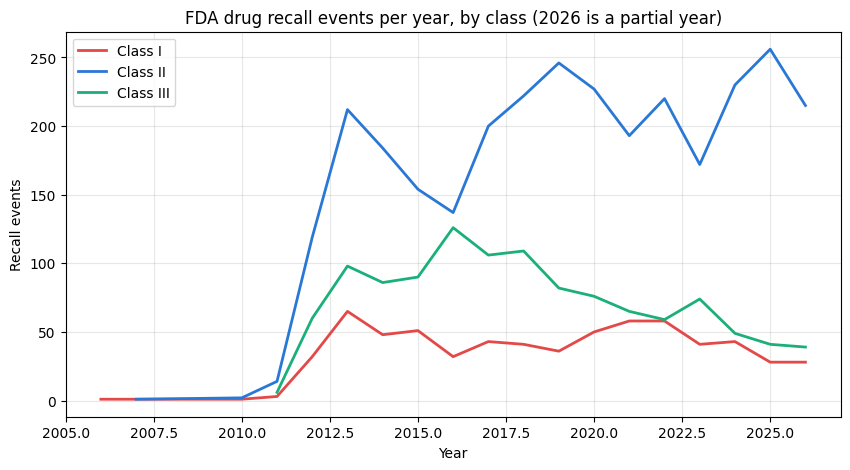


  SELECT TRIM(SPLIT(reason_for_recall, ':')[SAFE_OFFSET(0)]) AS reason,
         COUNT(DISTINCT event_id) AS n_events
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  GROUP BY reason
  ORDER BY n_events DESC
  LIMIT 10

Dry run: 0.0021 GB


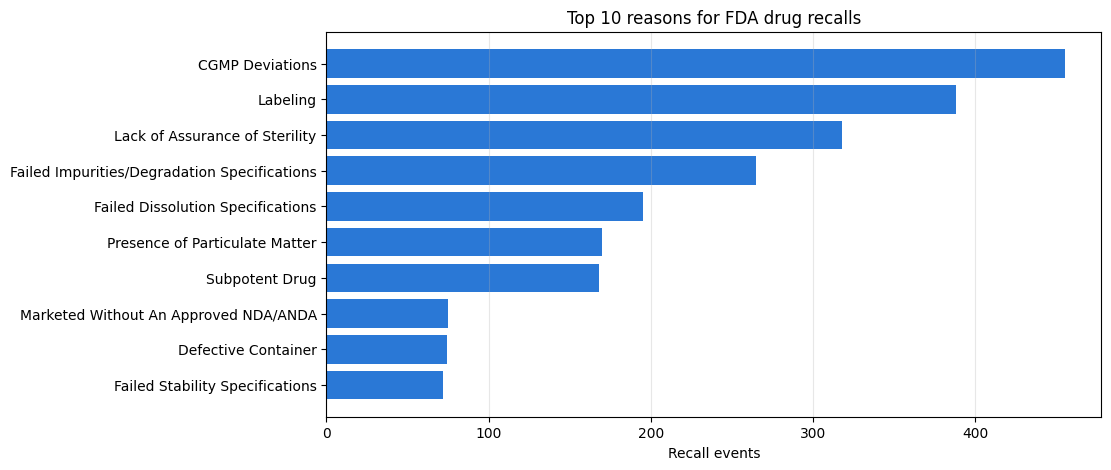

In [40]:
import matplotlib.pyplot as plt

# ---- Plot 1: Recall events per year, by class ----
query = '''
  SELECT EXTRACT(YEAR FROM recall_initiation_date) AS year,
         classification,
         COUNT(DISTINCT event_id) AS n_events
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  GROUP BY year, classification
'''
print(query)
by_class = bq_query(query)

fig, ax = plt.subplots(figsize=(10, 5))
colors = {'Class I': '#e34948', 'Class II': '#2a78d6', 'Class III': '#1baf7a'}
for cls, color in colors.items():
    # DuckDB picks out one class at a time from the small result
    part = duckdb.query(f'''
      SELECT year, n_events FROM by_class
      WHERE classification = '{cls}'
      ORDER BY year
    ''').df()
    ax.plot(part['year'], part['n_events'], label=cls, color=color, linewidth=2)
ax.set_title('FDA drug recall events per year, by class (2026 is a partial year)')
ax.set_xlabel('Year')
ax.set_ylabel('Recall events')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# ---- Plot 2: Top 10 reasons for recall ----
# The text before the colon is the recall category, e.g. "CGMP Deviations: ..."
query = '''
  SELECT TRIM(SPLIT(reason_for_recall, ':')[SAFE_OFFSET(0)]) AS reason,
         COUNT(DISTINCT event_id) AS n_events
  FROM `bigquery-public-data.fda_drug.drug_enforcement`
  GROUP BY reason
  ORDER BY n_events DESC
  LIMIT 10
'''
print(query)
reasons = bq_query(query)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(reasons['reason'][::-1], reasons['n_events'][::-1], color='#2a78d6')
ax.set_title('Top 10 reasons for FDA drug recalls')
ax.set_xlabel('Recall events')
ax.grid(axis='x', alpha=0.3)
plt.show()

## EXTRA CREDIT:

#### Use a query that joins two tables.


#### Make a model to see if you can predict something


#### Come up with something else cool to do with your data
